# Creating GFS Forecast Area & Time Cross-Sections 

In this example, we will download the GFS0P25 Forecast for Vertical Velocity up to 500mb and create area and time cross-sections across Lake Ontario for the next 72 hours *(I'm a SUNY Oswego Meteorology alumn Class 2016!!)* 

To make this more fun, we will convert the GRIB2 data to netCDF using the `gfs_0p25` client and then use xarray to read in the netCDF (.nc) file. We will also tell the client not to return the values to prevent using additional memory since we will be reading the values in from the netCDF file. 

***WxData GFS0P25 Client***
```python
def gfs_0p25(final_forecast_hour=384, 
            western_bound=-180, 
            eastern_bound=180, 
            northern_bound=90, 
            southern_bound=-90, 
            step=3,
            process_data=True,
            proxies=None, 
            variables=['geopotential height',
                       'temperature',
                       'relative humidity',
                       'u-component of wind',
                       'v-component of wind'],
            custom_directory=None,
            clear_recycle_bin=False,
            convert_temperature=True,
            convert_to='celsius',
            chunk_size=8192,
            notifications='off',
            clear_data=False,
            source='noaa',
            level_type='pressure',
            levels=[1000,
                    925,
                    850,
                    700,
                    500,
                    400,
                    300,
                    250,
                    200,
                    100,
                    50,
                    10],
            to_netcdf=False,
            netcdf_path=f"GFS0P25/NETCDF",
            netcdf_filename=f"gfs_0p25.nc",
            delete_previous_netcdf_file=True,
            return_values=True):
```
***WxData Pixel Query Tool***
```python
def pixel_query(ds, 
                latitude=None, 
                longitude=None,
                station_id=None,
                coord_names=['latitude',
                            'longitude'],
                proxies=None,
               grid_mapping_name='latitude_longitude'):
```
***WxData Line Query Tool***
```python
def line_query(ds, 
               starting_point,
               ending_point,
               coord_names=['latitude',
                            'longitude'],
               surface_pressure_key='surface_pressure',
               north_to_south=False,
               pressure_level_key='isobaricInhPa',
               proxies=None,
               grid_mapping_name='latitude_longitude'):
```

[GFS0P25 Client Documentation](https://edrewitz.github.io/WxData/GFS0P25)

[Pixel Query Documentation](https://edrewitz.github.io/WxData/pixel_query)

[Line Query Documentation](https://edrewitz.github.io/WxData/line_query)

## Imports

In [1]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.gridspec as gridspec
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
import pandas as pd
import xarray as xr

from datetime import timedelta
from wxdata import(
    gfs_0p25,
    pixel_query,
    line_query
)

### Download Our GFS0P25 Data & Export to NETCDF

In [2]:
gfs_0p25(
    final_forecast_hour=72,
    western_bound=-81.5,
    eastern_bound=-75.5,
    northern_bound=45.5,
    southern_bound=42.5,
    variables=['vertical velocity (pressure)'],
    levels=[1000, 925, 850, 700, 500],
    custom_directory=f"GFS0P25/Pressure",
    to_netcdf=True,
    netcdf_path=f"GFS0P25/Example/NETCDF",
    netcdf_filename=f"gfs_0p25_vv.nc",
    return_values=False
    )

Writing GRIB messages     |                              | 0/5

VVEL @ 1000 mb                 |                              |   0% [0.00/119k]

VVEL @ 500 mb                  |                              |   0% [0.00/142k]

VVEL @ 700 mb                  |                              |   0% [0.00/145k]

VVEL @ 850 mb                  |                              |   0% [0.00/149k]

...

VVEL @ 500 mb                  |                              |   0% [0.00/140k]

VVEL @ 700 mb                  |                              |   0% [0.00/144k]

VVEL @ 850 mb                  |                              |   0% [0.00/148k]

VVEL @ 925 mb                  |                              |   0% [0.00/146k]

GFS0P25 Download Complete
GFS0P25 Data Processing...
GFS0P25 Data Processing Complete.
gfs_0p25_vv.nc saved to GFS0P25/Example/NETCDF


In [3]:
# Since we just pulled from NOMADS - Let's pull from AWS on the surface fields

gfs_0p25(
    final_forecast_hour=72,
    western_bound=-81.5,
    eastern_bound=-75.5,
    northern_bound=45.5,
    southern_bound=42.5,
    variables=['pressure'],
    level_type='surface',
    source='aws',
    custom_directory=f"GFS0P25/Surface",
    to_netcdf=True,
    netcdf_path=f"GFS0P25/Example/NETCDF",
    netcdf_filename=f"gfs_0p25_pres.nc",
    return_values=False
    )

Writing GRIB messages     |                              | 0/1

PRES @ surface                 |                              |   0% [0.00/101k]

Writing GRIB messages     |                              | 0/1

PRES @ surface                 |                              |   0% [0.00/101k]

Writing GRIB messages     |                              | 0/1

...

Writing GRIB messages     |                              | 0/1

PRES @ surface                 |                              |   0% [0.00/102k]

Writing GRIB messages     |                              | 0/1

PRES @ surface                 |                              |   0% [0.00/101k]

GFS0P25 Download Complete
GFS0P25 Data Processing...
GFS0P25 Data Processing Complete.
gfs_0p25_pres.nc saved to GFS0P25/Example/NETCDF


### Extract Our Data From NETCDF Files

In [4]:
ds1 = xr.open_dataset(f"GFS0P25/Example/NETCDF/gfs_0p25_vv.nc", engine='netcdf4')

In [5]:
ds1

<xarray.Dataset> Size: 163kB
Dimensions:            (step: 25, isobaricInhPa: 5, latitude: 13,
                        longitude: 25, time: 25)
Coordinates:
  * step               (step) float64 200B 0.0 3.0 6.0 9.0 ... 66.0 69.0 72.0
  * isobaricInhPa      (isobaricInhPa) float64 40B 1e+03 925.0 850.0 700.0 500.0
  * latitude           (latitude) float64 104B 45.5 45.25 45.0 ... 42.75 42.5
  * longitude          (longitude) float64 200B -81.5 -81.25 ... -75.75 -75.5
  * time               (time) datetime64[ns] 200B 2026-10-30 ... 2026-11-02
    valid_time         datetime64[ns] 8B ...
Data variables:
    vertical_velocity  (step, isobaricInhPa, latitude, longitude) float32 162kB ...
Attributes:
    GRIB_edition:            2
    GRIB_centre:             kwbc
    GRIB_centreDescription:  US National Weather Service - NCEP
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             US National Weather Service - NCEP
    history:                 2026-10-29T22:02 GRIB to CDM+CF via cfgrib-0.9.1...

In [6]:
ds2 = xr.open_dataset(f"GFS0P25/Example/NETCDF/gfs_0p25_pres.nc", engine='netcdf4')

In [7]:
ds2

<xarray.Dataset> Size: 33kB
Dimensions:           (step: 25, latitude: 13, longitude: 25, time: 25)
Coordinates:
  * step              (step) float64 200B 0.0 3.0 6.0 9.0 ... 66.0 69.0 72.0
  * latitude          (latitude) float64 104B 45.5 45.25 45.0 ... 42.75 42.5
  * longitude         (longitude) float64 200B -81.5 -81.25 ... -75.75 -75.5
  * time              (time) datetime64[ns] 200B 2026-10-30 ... 2026-11-02
    surface           float64 8B ...
    valid_time        datetime64[ns] 8B ...
Data variables:
    surface_pressure  (step, latitude, longitude) float32 32kB ...
Attributes:
    GRIB_edition:            2
    GRIB_centre:             kwbc
    GRIB_centreDescription:  US National Weather Service - NCEP
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             US National Weather Service - NCEP
    history:                 2026-10-29T22:03 GRIB to CDM+CF via cfgrib-0.9.1...

### Create A Dataset of Both Fields

In [8]:
ds1['surface_pressure'] = ds2['surface_pressure']


In [9]:
ds = ds1

In [10]:
ds

<xarray.Dataset> Size: 196kB
Dimensions:            (step: 25, isobaricInhPa: 5, latitude: 13,
                        longitude: 25, time: 25)
Coordinates:
  * step               (step) float64 200B 0.0 3.0 6.0 9.0 ... 66.0 69.0 72.0
  * isobaricInhPa      (isobaricInhPa) float64 40B 1e+03 925.0 850.0 700.0 500.0
  * latitude           (latitude) float64 104B 45.5 45.25 45.0 ... 42.75 42.5
  * longitude          (longitude) float64 200B -81.5 -81.25 ... -75.75 -75.5
  * time               (time) datetime64[ns] 200B 2026-10-30 ... 2026-11-02
    valid_time         datetime64[ns] 8B ...
    surface            float64 8B ...
Data variables:
    vertical_velocity  (step, isobaricInhPa, latitude, longitude) float32 162kB ...
    surface_pressure   (step, latitude, longitude) float32 32kB ...
Attributes:
    GRIB_edition:            2
    GRIB_centre:             kwbc
    GRIB_centreDescription:  US National Weather Service - NCEP
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             US National Weather Service - NCEP
    history:                 2026-10-29T22:02 GRIB to CDM+CF via cfgrib-0.9.1...

### Line Query

We will create a west to east cross-section across Lake Ontario.

Western Point (Hamilton, Ontario): (43.25N/80.00W)

Eastern Point (Watertown, New York): (43.98N/-75.90N)

In [11]:
starting_point = (43.25, -80.00)
ending_point = (43.98, -75.90)

In [12]:
cross, pressure, index, lon, height = line_query(ds, 
               starting_point,
               ending_point)

In [13]:
cross

<xarray.Dataset> Size: 203kB
Dimensions:            (step: 25, isobaricInhPa: 5, index: 100)
Coordinates:
  * step               (step) float64 200B 0.0 3.0 6.0 9.0 ... 66.0 69.0 72.0
  * isobaricInhPa      (isobaricInhPa) float64 40B 1e+03 925.0 850.0 700.0 500.0
  * index              (index) int64 800B 0 1 2 3 4 5 6 ... 93 94 95 96 97 98 99
    longitude          (index) float64 800B -80.0 -79.96 -79.92 ... -75.94 -75.9
    latitude           (index) float64 800B 43.25 43.26 43.27 ... 43.97 43.98
    valid_time         datetime64[ns] 8B 2026-10-30
    surface            float64 8B 0.0
    metpy_crs          object 8B Projection: latitude_longitude
Data variables:
    vertical_velocity  (step, isobaricInhPa, index) float64 100kB 0.113 ... 0...
    surface_pressure   (step, isobaricInhPa, index) float64 100kB 9.897e+04 ....
Attributes:
    GRIB_edition:            2
    GRIB_centre:             kwbc
    GRIB_centreDescription:  US National Weather Service - NCEP
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             US National Weather Service - NCEP
    history:                 2026-10-29T22:02 GRIB to CDM+CF via cfgrib-0.9.1...

In [14]:
# Extract our y-axis (pressure coordinate) data for our cross-section
y_data = cross.coords["isobaricInhPa"].values  

# Extract the vertical velocity and longitude data from our cross-section
omega = cross['vertical_velocity'].metpy.dequantify().values
lon = cross['longitude'].metpy.dequantify().values

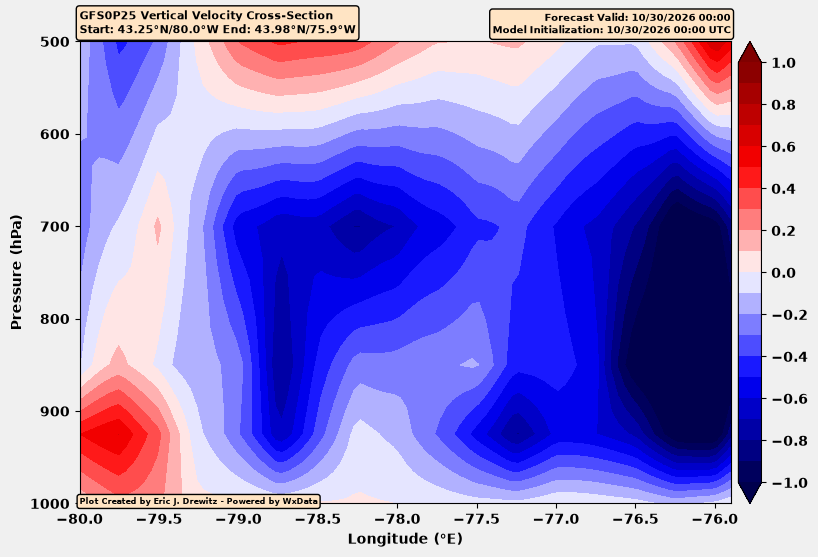

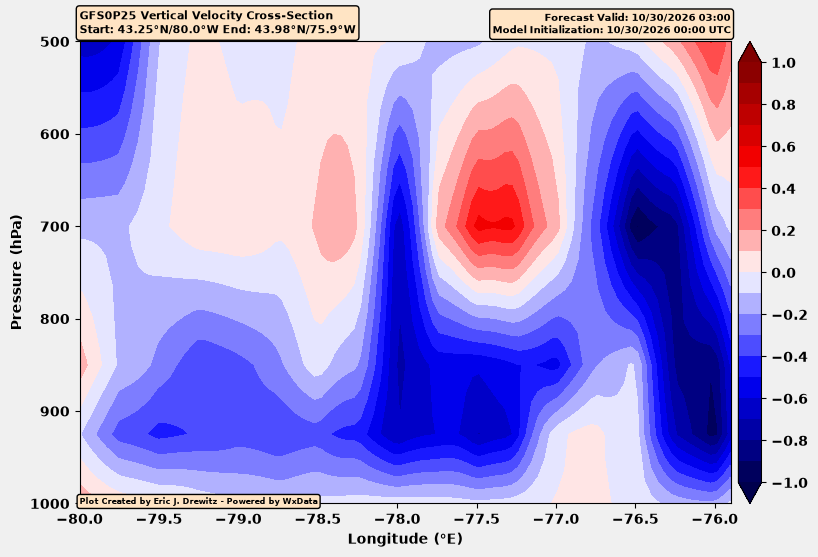

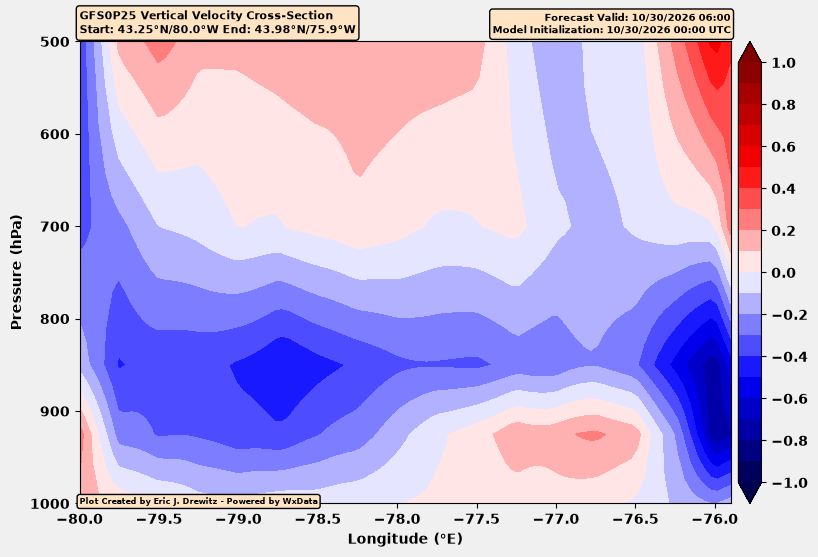

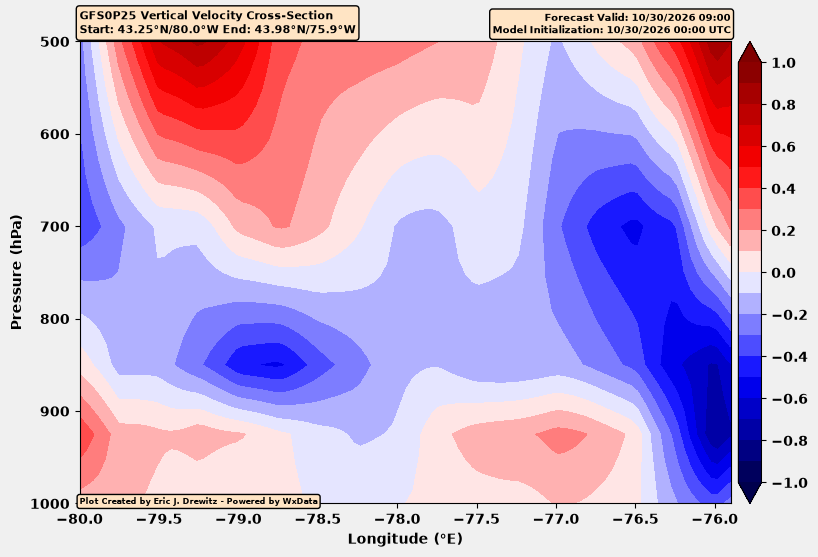

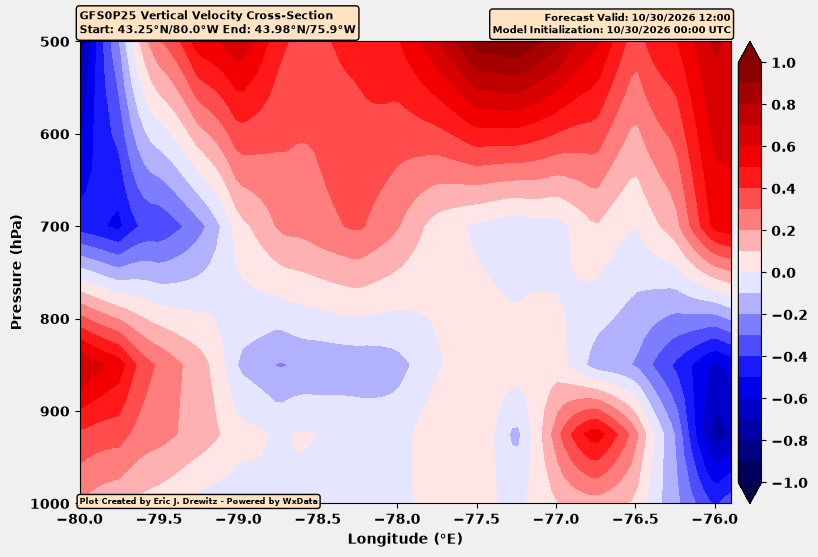

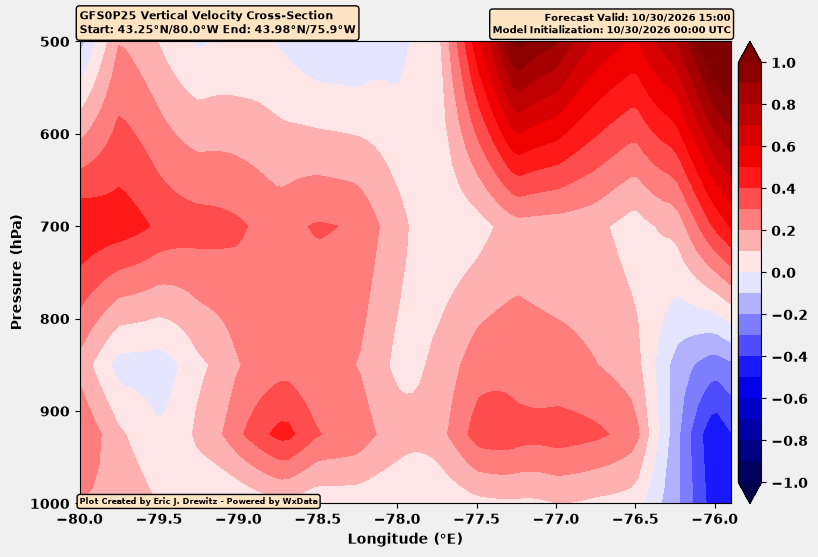

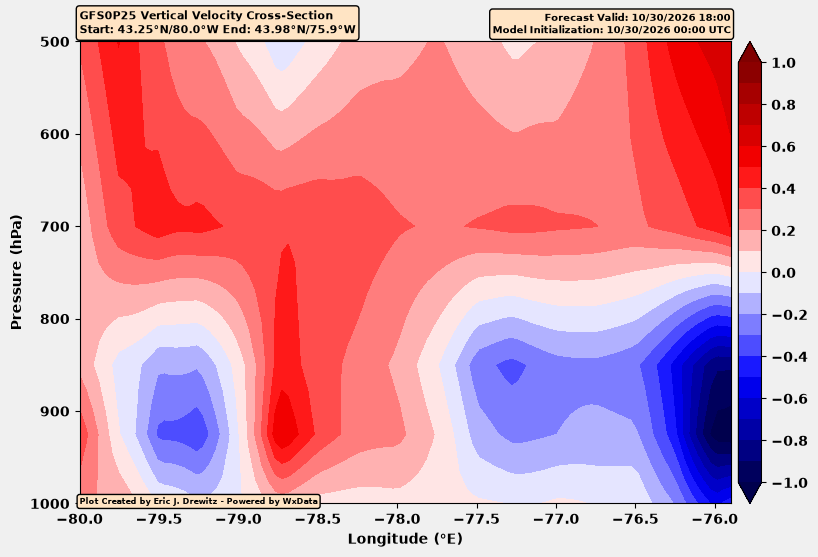

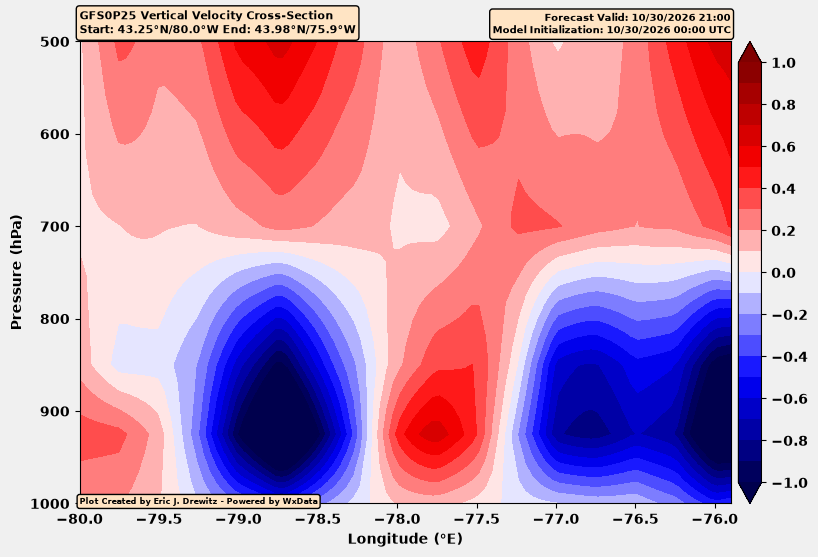

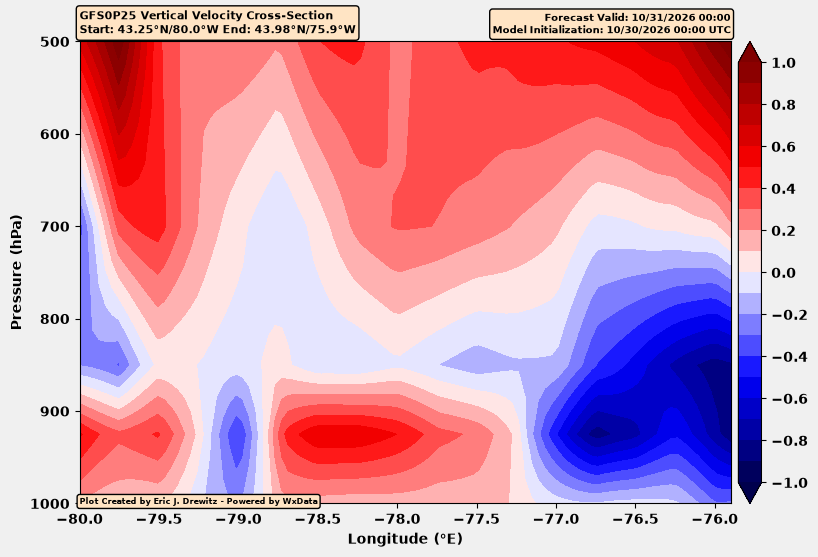

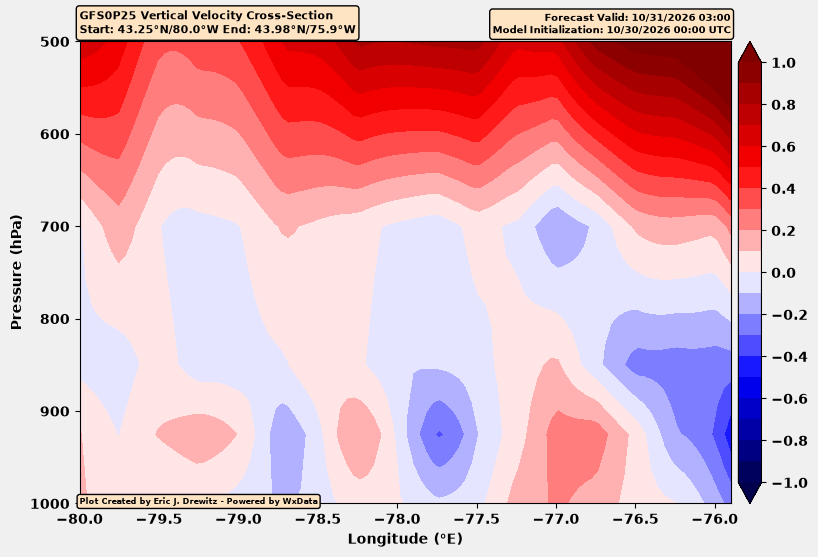

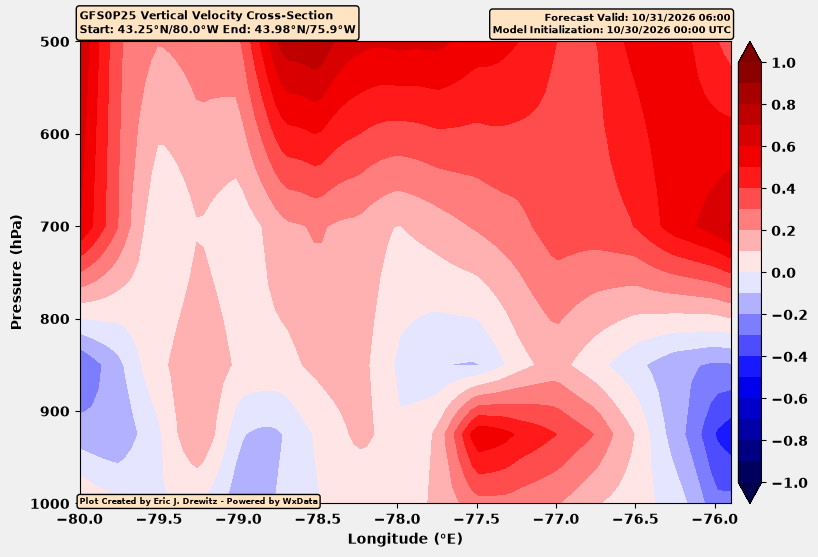

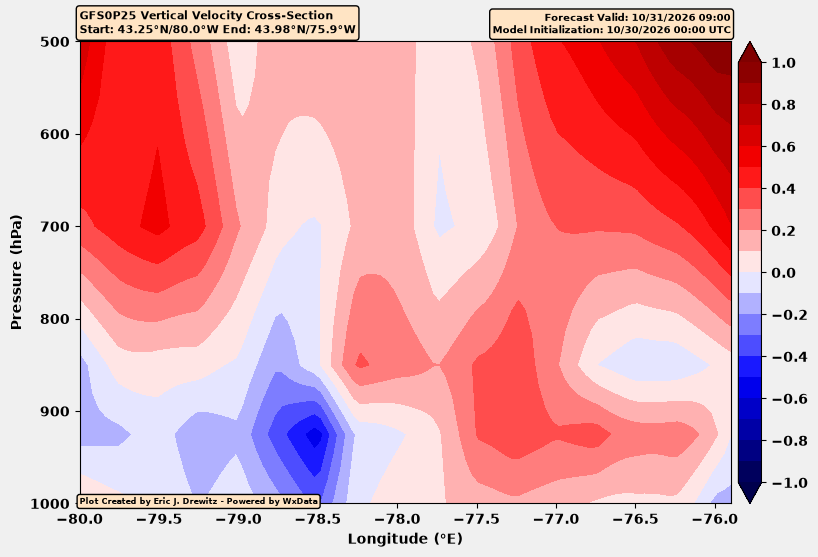

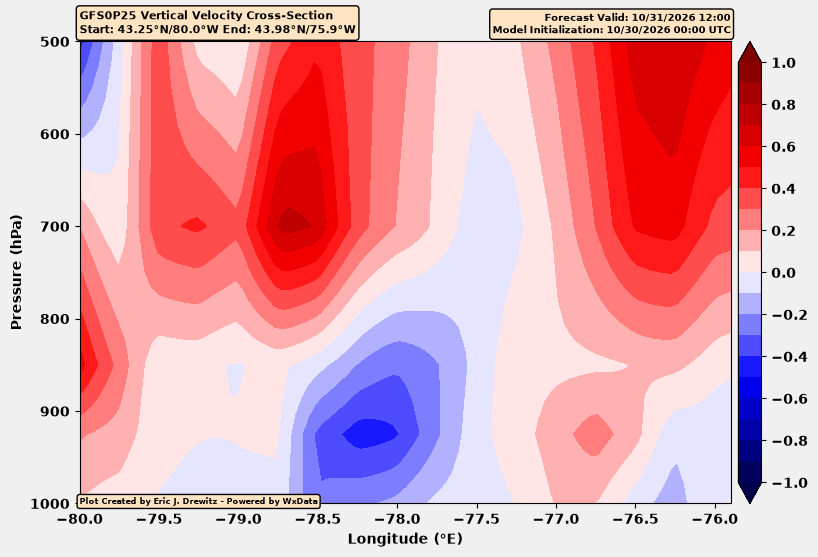

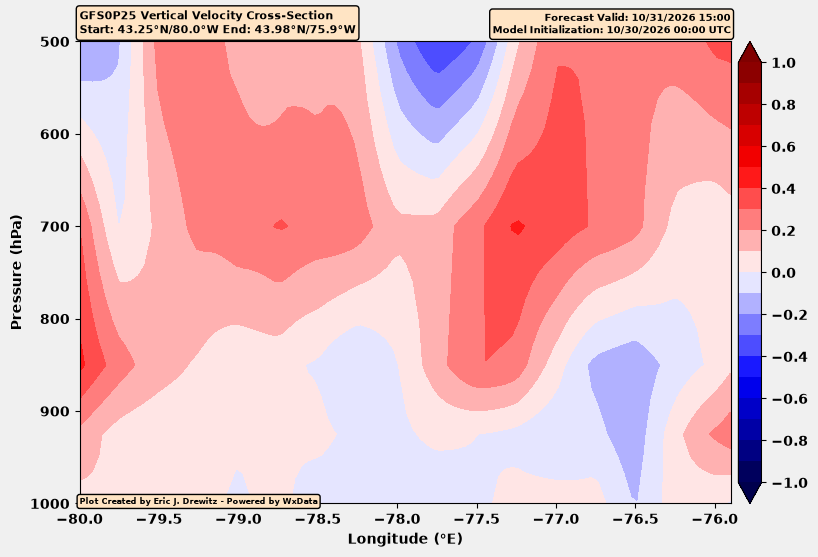

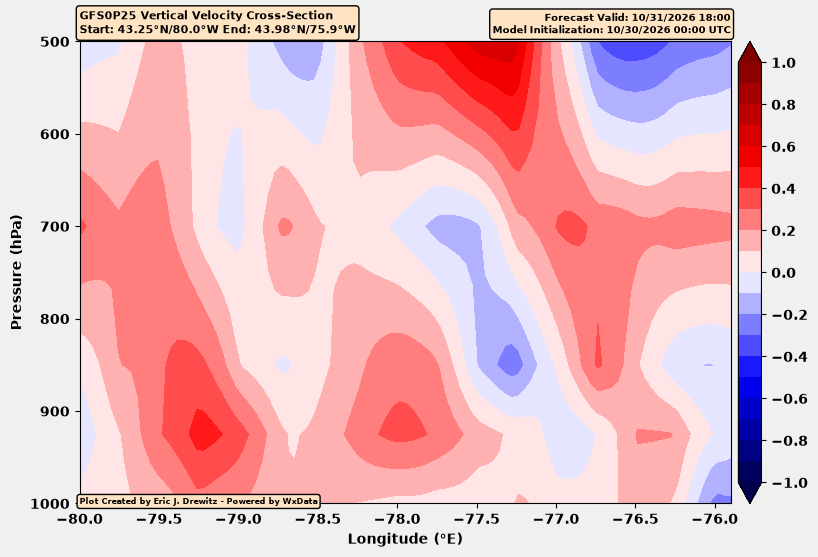

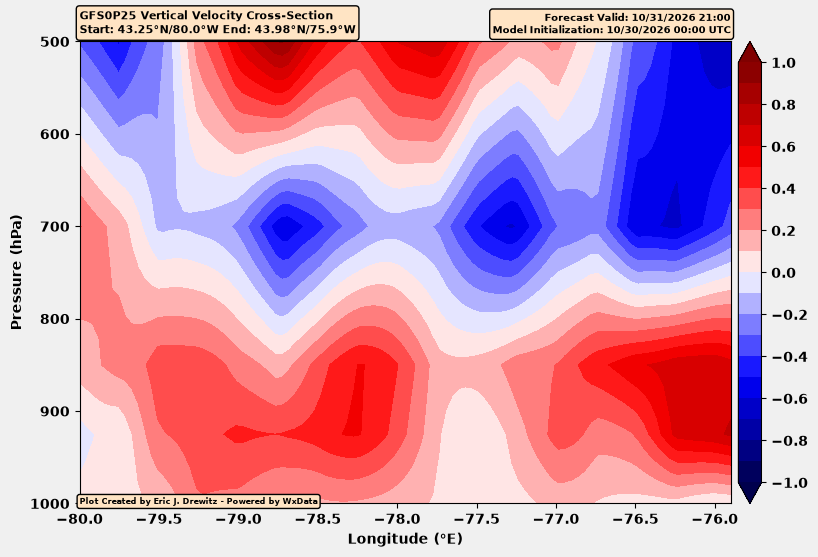

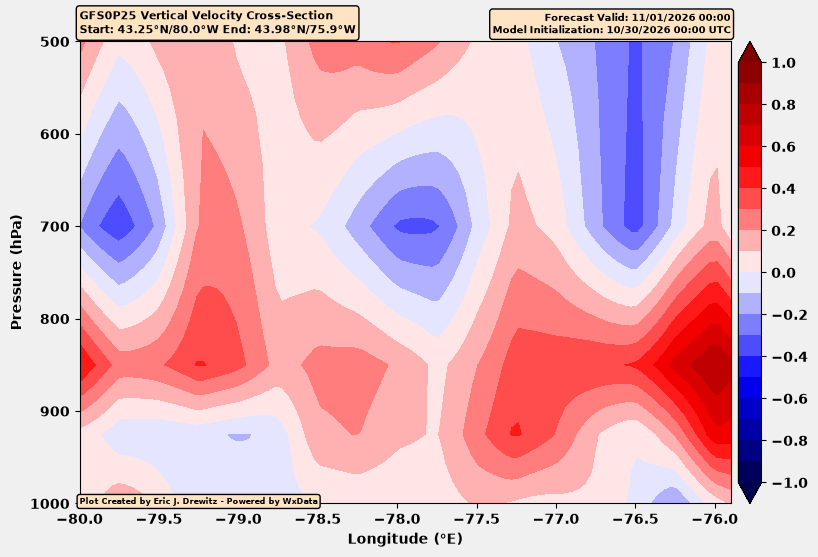

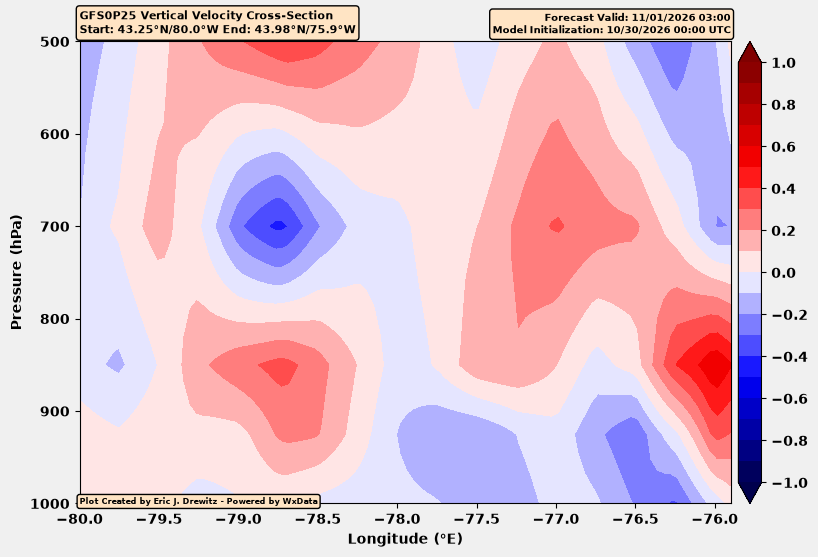

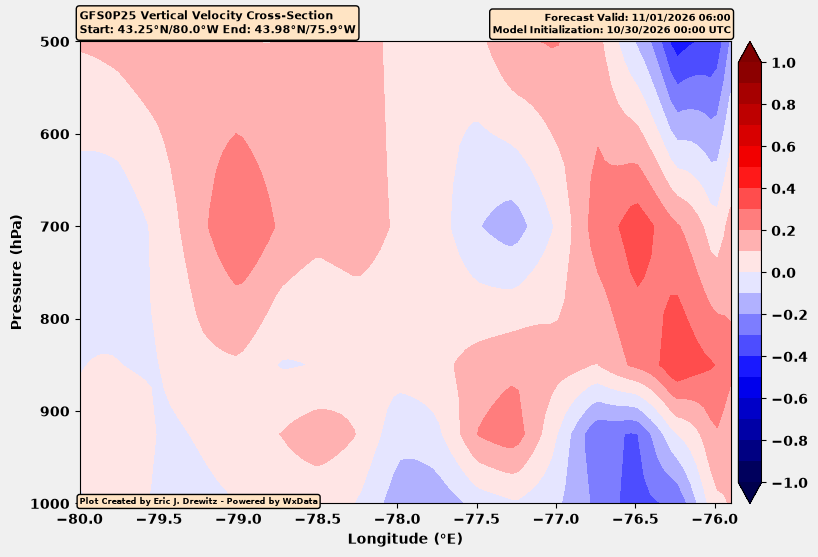

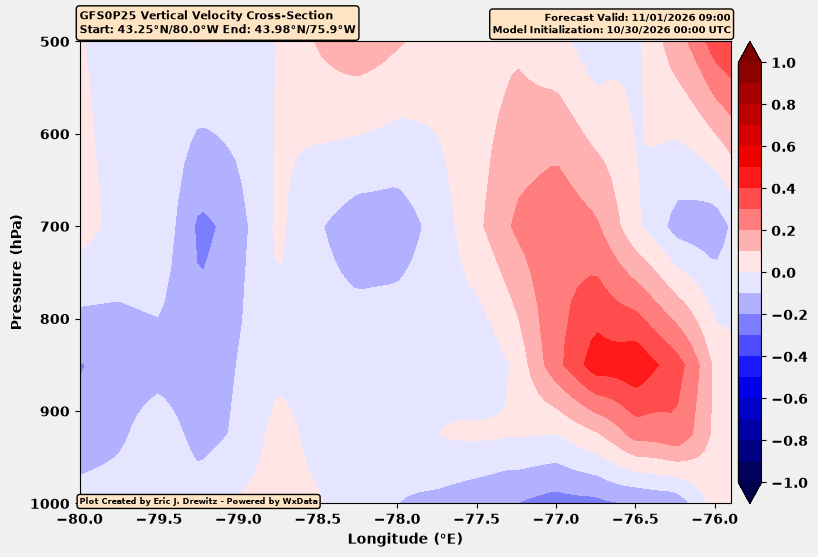

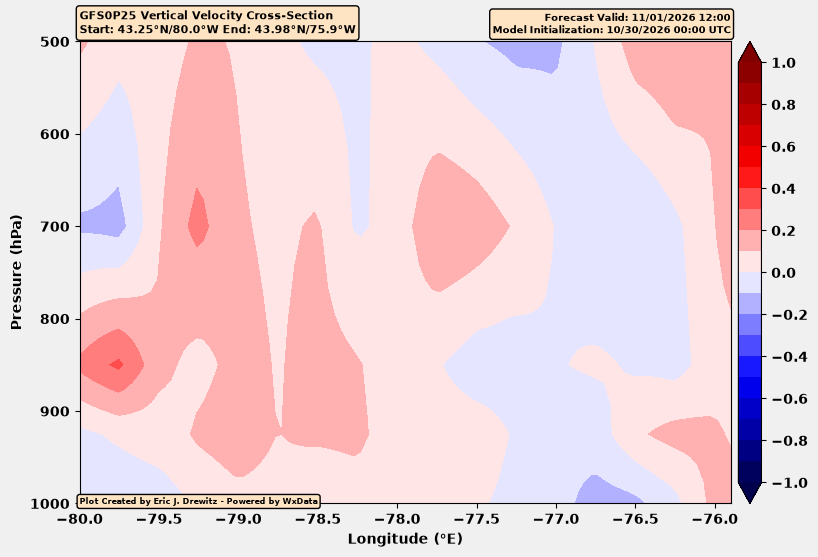

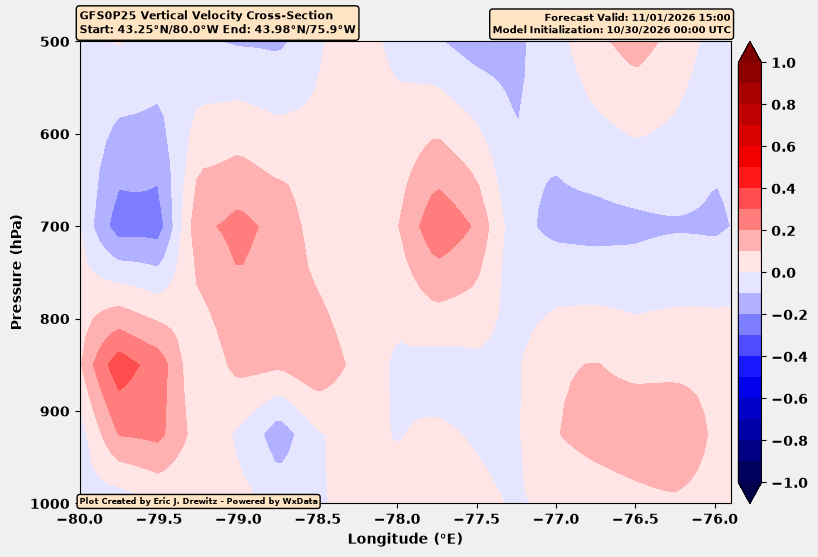

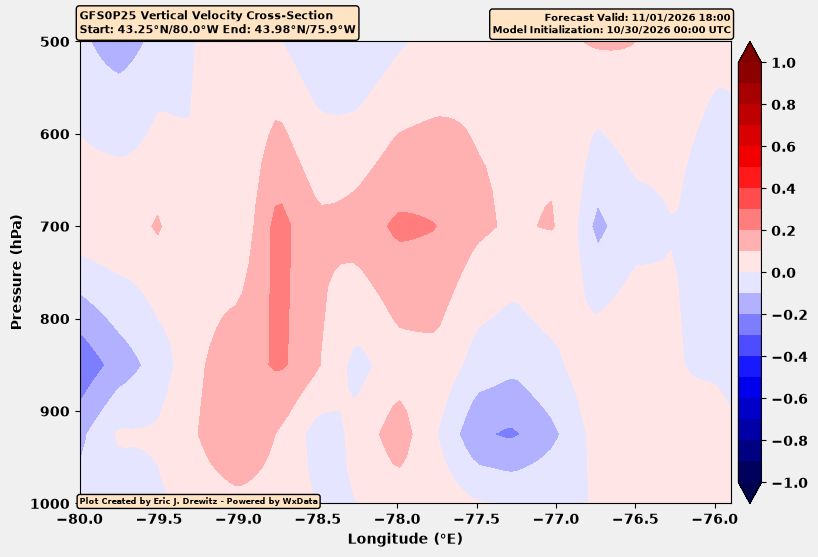

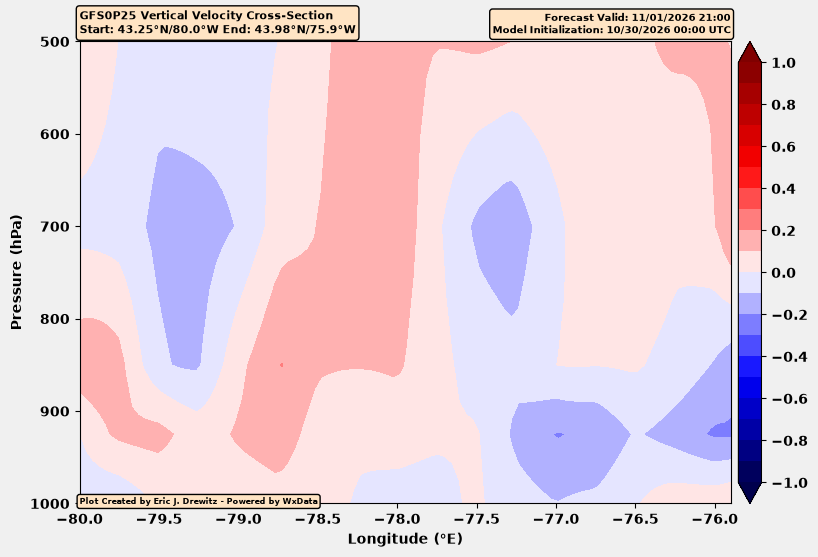

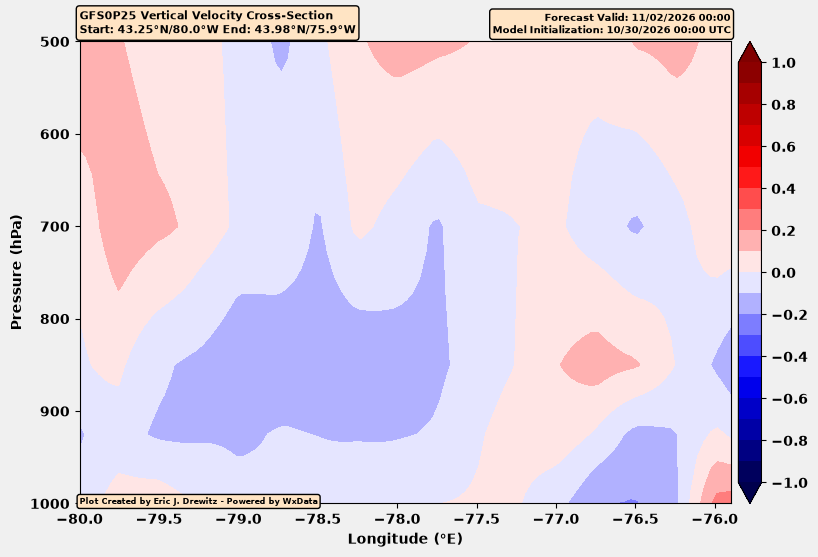

In [15]:
# Set bold for all text on plot
plt.rcParams['font.weight'] = 'bold'

# Create our cross-sections for each forecast time
for i in range(0, len(ds['step']), 1):

    # Create our figure
    fig, ax = plt.subplots(figsize=(10, 6))

    # Set the figure facecolor to gray
    fig.set_facecolor('#f0f0f0')
    
    # Plot the vertical velocity data
    cs = ax.contourf(lon, 
                     y_data, 
                     omega[i, :, :], 
                     cmap="seismic", 
                     levels=np.arange(-1, 1.1, 0.1),
                     extend='both')
    
    # Add a colorbar
    cbar = fig.colorbar(cs, 
                        ax=ax, 
                        orientation="vertical",
                        ticks=np.arange(-1, 1.2, 0.2),
                        pad=0.01)
    
    # Invert the Y-axis if using Pressure levels
    ax.set_ylim(y_data.max(), y_data.min())    

    # Label our x and y axes
    ax.set_xlabel("Longitude (°E)", fontweight='bold')
    ax.set_ylabel("Pressure (hPa)", fontweight='bold')

    # Primary Plot title
    plt.title(f"GFS0P25 Vertical Velocity Cross-Section\nStart: {starting_point[0]}°N/{abs(starting_point[1])}°W End: {ending_point[0]}°N/{abs(ending_point[1])}°W", 
                   fontsize=8, 
                   fontweight='bold',
                   bbox=dict(boxstyle='round', 
                                facecolor='bisque'),
                   loc='left')

    # Extract our time data for the second title
    time = pd.to_datetime(ds['time'].values)
    
    # Secondary title for forecast and initialization times
    plt.title(f"Forecast Valid: {time[i].strftime('%m/%d/%Y %H:00')}\nModel Initialization: {time[0].strftime('%m/%d/%Y %H:00')} UTC", 
                    fontsize=7, 
                    fontweight='bold',
                    bbox=dict(boxstyle='round', 
                                facecolor='bisque'),
                    loc='right')
    
    # Adding my signature on the plot
    ax.text(0, 
            -0.001, 
            f"Plot Created by Eric J. Drewitz - Powered by WxData", 
            transform=ax.transAxes, 
            fontsize=6, 
            fontweight='bold', 
            bbox=dict(boxstyle='round', 
                    facecolor='bisque'),
           zorder=10)
    
    plt.show()

## Pixel Query

In [16]:
point = pixel_query(ds,
                    latitude=43.62,
                    longitude=-77.40)

In [17]:
point

<xarray.Dataset> Size: 880B
Dimensions:            (step: 25, isobaricInhPa: 5)
Coordinates:
  * step               (step) float64 200B 0.0 3.0 6.0 9.0 ... 66.0 69.0 72.0
  * isobaricInhPa      (isobaricInhPa) float64 40B 1e+03 925.0 850.0 700.0 500.0
    latitude           float64 8B 43.5
    valid_time         datetime64[ns] 8B 2026-10-30
    longitude          float64 8B -77.5
    surface            float64 8B 0.0
    metpy_crs          object 8B Projection: latitude_longitude
Data variables:
    vertical_velocity  (step, isobaricInhPa) float32 500B ...
    surface_pressure   (step) float32 100B ...
Attributes:
    GRIB_edition:            2
    GRIB_centre:             kwbc
    GRIB_centreDescription:  US National Weather Service - NCEP
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             US National Weather Service - NCEP
    history:                 2026-10-29T22:02 GRIB to CDM+CF via cfgrib-0.9.1...

In [18]:
# Extracts our initialization time and steps
time = ds['valid_time'].values
steps = ds['step'].values

In [19]:
time

np.datetime64('2026-10-30T00:00:00.000000000')

In [20]:
steps

array([ 0.,  3.,  6.,  9., 12., 15., 18., 21., 24., 27., 30., 33., 36.,
       39., 42., 45., 48., 51., 54., 57., 60., 63., 66., 69., 72.])

In [21]:
# Creates a new array of forecast valid times
times = []
for s in steps:
    t = pd.to_datetime(time) + timedelta(hours=s)
    times.append(t)

In [22]:
times

[Timestamp('2026-10-30 00:00:00'),
 Timestamp('2026-10-30 03:00:00'),
 Timestamp('2026-10-30 06:00:00'),
 Timestamp('2026-10-30 09:00:00'),
 Timestamp('2026-10-30 12:00:00'),
 Timestamp('2026-10-30 15:00:00'),
 Timestamp('2026-10-30 18:00:00'),
 Timestamp('2026-10-30 21:00:00'),
 Timestamp('2026-10-31 00:00:00'),
 Timestamp('2026-10-31 03:00:00'),
 Timestamp('2026-10-31 06:00:00'),
 Timestamp('2026-10-31 09:00:00'),
 Timestamp('2026-10-31 12:00:00'),
 Timestamp('2026-10-31 15:00:00'),
 Timestamp('2026-10-31 18:00:00'),
 Timestamp('2026-10-31 21:00:00'),
 Timestamp('2026-11-01 00:00:00'),
 Timestamp('2026-11-01 03:00:00'),
 Timestamp('2026-11-01 06:00:00'),
 Timestamp('2026-11-01 09:00:00'),
 Timestamp('2026-11-01 12:00:00'),
 Timestamp('2026-11-01 15:00:00'),
 Timestamp('2026-11-01 18:00:00'),
 Timestamp('2026-11-01 21:00:00'),
 Timestamp('2026-11-02 00:00:00')]

In [23]:
# Adds the new array of forecast valid times to the point forecast data array
point['time'] = times

In [24]:
point

<xarray.Dataset> Size: 1kB
Dimensions:            (step: 25, isobaricInhPa: 5, time: 25)
Coordinates:
  * step               (step) float64 200B 0.0 3.0 6.0 9.0 ... 66.0 69.0 72.0
  * isobaricInhPa      (isobaricInhPa) float64 40B 1e+03 925.0 850.0 700.0 500.0
  * time               (time) datetime64[ns] 200B 2026-10-30 ... 2026-11-02
    latitude           float64 8B 43.5
    valid_time         datetime64[ns] 8B 2026-10-30
    longitude          float64 8B -77.5
    surface            float64 8B 0.0
    metpy_crs          object 8B Projection: latitude_longitude
Data variables:
    vertical_velocity  (step, isobaricInhPa) float32 500B ...
    surface_pressure   (step) float32 100B ...
Attributes:
    GRIB_edition:            2
    GRIB_centre:             kwbc
    GRIB_centreDescription:  US National Weather Service - NCEP
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             US National Weather Service - NCEP
    history:                 2026-10-29T22:02 GRIB to CDM+CF via cfgrib-0.9.1...

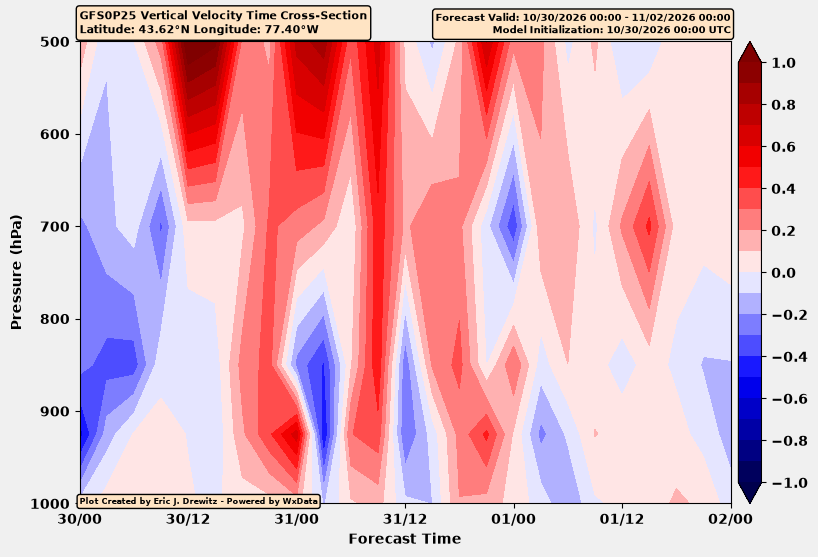

In [25]:
# Set bold for all text on plot
plt.rcParams['font.weight'] = 'bold'

# Create the Matplotlib figure
fig, ax = plt.subplots(figsize=(10, 6))

# Set the figure facecolor to gray
fig.set_facecolor('#f0f0f0')

# Plot the vertical velocity data
cs = ax.contourf(point['time'], 
                 point['isobaricInhPa'], 
                 point['vertical_velocity'].T, 
                 cmap="seismic", 
                 levels=np.arange(-1, 1.1, 0.1),
                 extend='both')

# Add a colorbar
cbar = fig.colorbar(cs, 
                    ax=ax, 
                    orientation="vertical",
                    ticks=np.arange(-1, 1.2, 0.2),
                    pad=0.01)

# Invert the Y-axis if using Pressure levels
ax.set_ylim(y_data.max(), y_data.min())    

# Label our x and y axes
ax.set_xlabel("Forecast Time", fontweight='bold')
ax.set_ylabel("Pressure (hPa)", fontweight='bold')

# Primary plot title
plt.title(f"GFS0P25 Vertical Velocity Time Cross-Section\nLatitude: 43.62°N Longitude: 77.40°W", 
               fontsize=8, 
               fontweight='bold',
               bbox=dict(boxstyle='round', 
                            facecolor='bisque'),
               loc='left')

# Creates an array of our datetime objects for forecast valid times
time = pd.to_datetime(ds['time'].values)
# Secondary title for our model runtime
plt.title(f"Forecast Valid: {time[0].strftime('%m/%d/%Y %H:00')} - {time[-1].strftime('%m/%d/%Y %H:00')}\nModel Initialization: {time[0].strftime('%m/%d/%Y %H:00')} UTC", 
                fontsize=7, 
                fontweight='bold',
                bbox=dict(boxstyle='round', 
                            facecolor='bisque'),
                loc='right')

# Adding my signature on the plot
ax.text(0, 
        -0.001, 
        f"Plot Created by Eric J. Drewitz - Powered by WxData", 
        transform=ax.transAxes, 
        fontsize=6, 
        fontweight='bold', 
        bbox=dict(boxstyle='round', 
                facecolor='bisque'),
       zorder=10)

# Formats the x-axis using datetime
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d/%H'))

plt.show()